# Red Wine Quality ML Pipeline

Predict whether a red wine is rated **good** (quality >= 6) from its physicochemical measurements.

Dataset: [Red Wine Quality](https://www.kaggle.com/datasets/uciml/red-wine-quality-cortez-et-al-2009)

## 1. Setup

In [42]:
import os

import kagglehub
import matplotlib.pyplot as plt
import pandas as pd
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler

# Config
DATASET = "uciml/red-wine-quality-cortez-et-al-2009/versions/2"  # pinned dataset version
CSV_NAME = "winequality-red.csv"
RANDOM_STATE = 42  # fixed seed so results are reproducible
TEST_SIZE = 0.2
GOOD_THRESHOLD = 6  # quality >= this counts as a "good" wine

FEATURES = [
    "fixed acidity", "volatile acidity", "citric acid", "residual sugar", "chlorides",
    "free sulfur dioxide", "total sulfur dioxide", "density", "pH", "sulphates", "alcohol",
]
TARGET = "quality"

## 2. Load and validate data

In [43]:
path = kagglehub.dataset_download(DATASET)
print("Path to dataset files:", path)

df = pd.read_csv(os.path.join(path, CSV_NAME))
print(df.shape)
df.head()

Path to dataset files: /Users/jakubromanczuk/.cache/kagglehub/datasets/uciml/red-wine-quality-cortez-et-al-2009/versions/2
(1599, 12)


,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality
0,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5
1,7.8,0.88,0.00,2.6,0.098,25.0,67.0,0.9968,3.20,0.68,9.8,5
2,7.8,0.76,0.04,2.3,0.092,15.0,54.0,0.9970,3.26,0.65,9.8,5
3,11.2,0.28,0.56,1.9,0.075,17.0,60.0,0.9980,3.16,0.58,9.8,6
4,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5


In [44]:
# Fail early with a clear message if the dataset doesn't look like we expect
missing_cols = set(FEATURES + [TARGET]) - set(df.columns)
assert not missing_cols, f"Missing expected columns: {missing_cols}"
assert df[FEATURES + [TARGET]].dtypes.map(pd.api.types.is_numeric_dtype).all(), "Non-numeric column found"
print("Schema OK")

Schema OK


## 3. Clean

In [45]:
print("Missing values:", df.isna().sum().sum())

# Duplicate rows can land in both train and test and inflate accuracy, so drop them
print("Duplicate rows:", df.duplicated().sum())
df = df.drop_duplicates().reset_index(drop=True)
print("Shape after dropping duplicates:", df.shape)

Missing values: 0
Duplicate rows: 240
Shape after dropping duplicates: (1359, 12)


## 4. Target

`good = quality >= 6` (binary).

In [46]:
df["good"] = (df[TARGET] >= GOOD_THRESHOLD).astype(int)

print(df["good"].value_counts().sort_index())
print(df["good"].value_counts(normalize=True).sort_index().round(3))

good
0    640
1    719
Name: count, dtype: int64
good
0    0.471
1    0.529
Name: proportion, dtype: float64


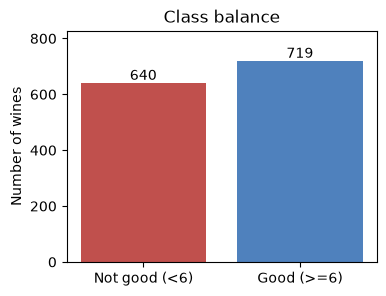

In [47]:
counts = df["good"].value_counts().sort_index()  # 0 = not good, 1 = good
fig, ax = plt.subplots(figsize=(4, 3))
bars = ax.bar(
    [f"Not good (<{GOOD_THRESHOLD})", f"Good (>={GOOD_THRESHOLD})"],
    counts.values,
    color=["#c0504d", "#4f81bd"],
)
ax.bar_label(bars)
ax.set_ylim(0, counts.max() * 1.15)
ax.set_ylabel("Number of wines")
ax.set_title("Class balance")
plt.show()

## 5. Quick EDA

In [48]:
df[FEATURES + [TARGET]].describe().T

,count,mean,std,min,25%,50%,75%,max
fixed acidity,1359.0,8.310596,1.736990,4.60000,7.1000,7.9000,9.20000,15.90000
volatile acidity,1359.0,0.529478,0.183031,0.12000,0.3900,0.5200,0.64000,1.58000
citric acid,1359.0,0.272333,0.195537,0.00000,0.0900,0.2600,0.43000,1.00000
residual sugar,1359.0,2.523400,1.352314,0.90000,1.9000,2.2000,2.60000,15.50000
chlorides,1359.0,0.088124,0.049377,0.01200,0.0700,0.0790,0.09100,0.61100
free sulfur dioxide,1359.0,15.893304,10.447270,1.00000,7.0000,14.0000,21.00000,72.00000
total sulfur dioxide,1359.0,46.825975,33.408946,6.00000,22.0000,38.0000,63.00000,289.00000
density,1359.0,0.996709,0.001869,0.99007,0.9956,0.9967,0.99782,1.00369
pH,1359.0,3.309787,0.155036,2.74000,3.2100,3.3100,3.40000,4.01000
sulphates,1359.0,0.658705,0.170667,0.33000,0.5500,0.6200,0.73000,2.00000


In [49]:
# Which features move with quality?
df[FEATURES + [TARGET]].corr()[TARGET].drop(TARGET).sort_values().round(3)

volatile acidity       -0.395
density                -0.184
total sulfur dioxide   -0.178
chlorides              -0.131
pH                     -0.055
free sulfur dioxide    -0.050
residual sugar          0.014
fixed acidity           0.119
citric acid             0.228
sulphates               0.249
alcohol                 0.480
Name: quality, dtype: float64

## 6. Train/test split

In [50]:
# `quality` is NOT a feature: `good` is derived from it, so including it would leak the answer
X = df[FEATURES]
y = df["good"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=TEST_SIZE, stratify=y, random_state=RANDOM_STATE
)

print("Train:", X_train.shape, "| Test:", X_test.shape)
print("Share of good wines  train:", round(y_train.mean(), 3), "| test:", round(y_test.mean(), 3))

Train: (1087, 11) | Test: (272, 11)
Share of good wines  train: 0.529 | test: 0.529


## 7. Model

In [51]:
# Scaler lives inside the pipeline, so it is fitted on training data only (no leakage)
model = Pipeline([
    ("scaler", StandardScaler()),
    ("clf", LogisticRegression(max_iter=1000, random_state=RANDOM_STATE)),
])
model.fit(X_train, y_train)
y_pred = model.predict(X_test)

# First few test wines: actual vs predicted (1 = good, 0 = not good)
pd.DataFrame({"actual": y_test.values, "predicted": y_pred}).head(10)

,actual,predicted
0,0,1
1,0,0
2,0,1
3,0,0
4,1,1
5,1,1
6,1,1
7,0,0
8,1,1
9,1,1


## 8. Evaluate

In [52]:
accuracy = accuracy_score(y_test, y_pred)
baseline = max(y_test.mean(), 1 - y_test.mean())  # always guess the majority class

print(f"Test accuracy: {accuracy:.3f}")
print(f"Baseline (always majority class): {baseline:.3f}")
print("\nConfusion matrix (rows = actual, cols = predicted):")
print(confusion_matrix(y_test, y_pred))
print("\n", classification_report(y_test, y_pred, target_names=["not good", "good"]))

Test accuracy: 0.735
Baseline (always majority class): 0.529

Confusion matrix (rows = actual, cols = predicted):
[[ 95  33]
 [ 39 105]]

               precision    recall  f1-score   support

    not good       0.71      0.74      0.73       128
        good       0.76      0.73      0.74       144

    accuracy                           0.74       272
   macro avg       0.73      0.74      0.73       272
weighted avg       0.74      0.74      0.74       272

